In [ ]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from IPython.display import display
import pandas as pd
from imblearn.over_sampling import RandomOverSampler
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [ ]:
# Framingham Heart Study dataset, commonly used for cardiovascular disease risk prediction. It typically includes demographics, behavioral factors, clinical measurements, and a binary target (10-year CHD risk).
df = pd.read_csv("/content/framingham.csv")

In [ ]:
df.head(10)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
5,0,43,2.0,0,0.0,0.0,0,1,0,228.0,180.0,110.0,30.30,77.0,99.0,0
6,0,63,1.0,0,0.0,0.0,0,0,0,205.0,138.0,71.0,33.11,60.0,85.0,1
7,0,45,2.0,1,20.0,0.0,0,0,0,313.0,100.0,71.0,21.68,79.0,78.0,0
8,1,52,1.0,0,0.0,0.0,0,1,0,260.0,141.5,89.0,26.36,76.0,79.0,0
9,1,43,1.0,1,30.0,0.0,0,1,0,225.0,162.0,107.0,23.61,93.0,88.0,0


In [ ]:
df.tail(10)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4230,0,56,1.0,1,3.0,0.0,0,1,0,268.0,170.0,102.0,22.89,57.0,NaN,0
4231,1,58,3.0,0,0.0,0.0,0,1,0,187.0,141.0,81.0,24.96,80.0,81.0,0
4232,1,68,1.0,0,0.0,0.0,0,1,0,176.0,168.0,97.0,23.14,60.0,79.0,1
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,0,39,3.0,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0


In [ ]:
df.shape #(Number of Rows, Number of Columns)

(4240, 16)

In [ ]:
df.isnull().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [ ]:
x = df.drop(columns = "TenYearCHD")
y = df.TenYearCHD

# Splitting the dataset into Training data and Testing Data in the ratio 8:2.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

# Splitting the Training data further into Training data and Validation Data in the ratio 8:2.
# So, final ratios are: Training Data -> 80% of 80%  = 64 %, Testing Data = 20 %, Validation Data -> 20% of 80% = 16 %.
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size = 0.2, random_state = 42, stratify = y_train)

**USE OF STRATIFY = Y and STRATIFY = Y_TRAIN**

It keeps the same class proportion in every split (train / validation / test) as in the original dataset.

**WHAT HAPPENS WHEN WE DON'T USE STRATIFY?**

Imagine a dataset of 100 patients in which O(No CHD) are 85 and 1(CHD) is 15.

That’s 85% negative, 15% positive.

Now when we train our model on data which is split without using stratification, the test split of 20 entries will give let's say 19 0(No CHD) and 1(CHD) because the model barely sees positive values and the evaluation metric become misleading.

**Without using stratify the model might be accurate but clinially(for medical datasets) it fails.**

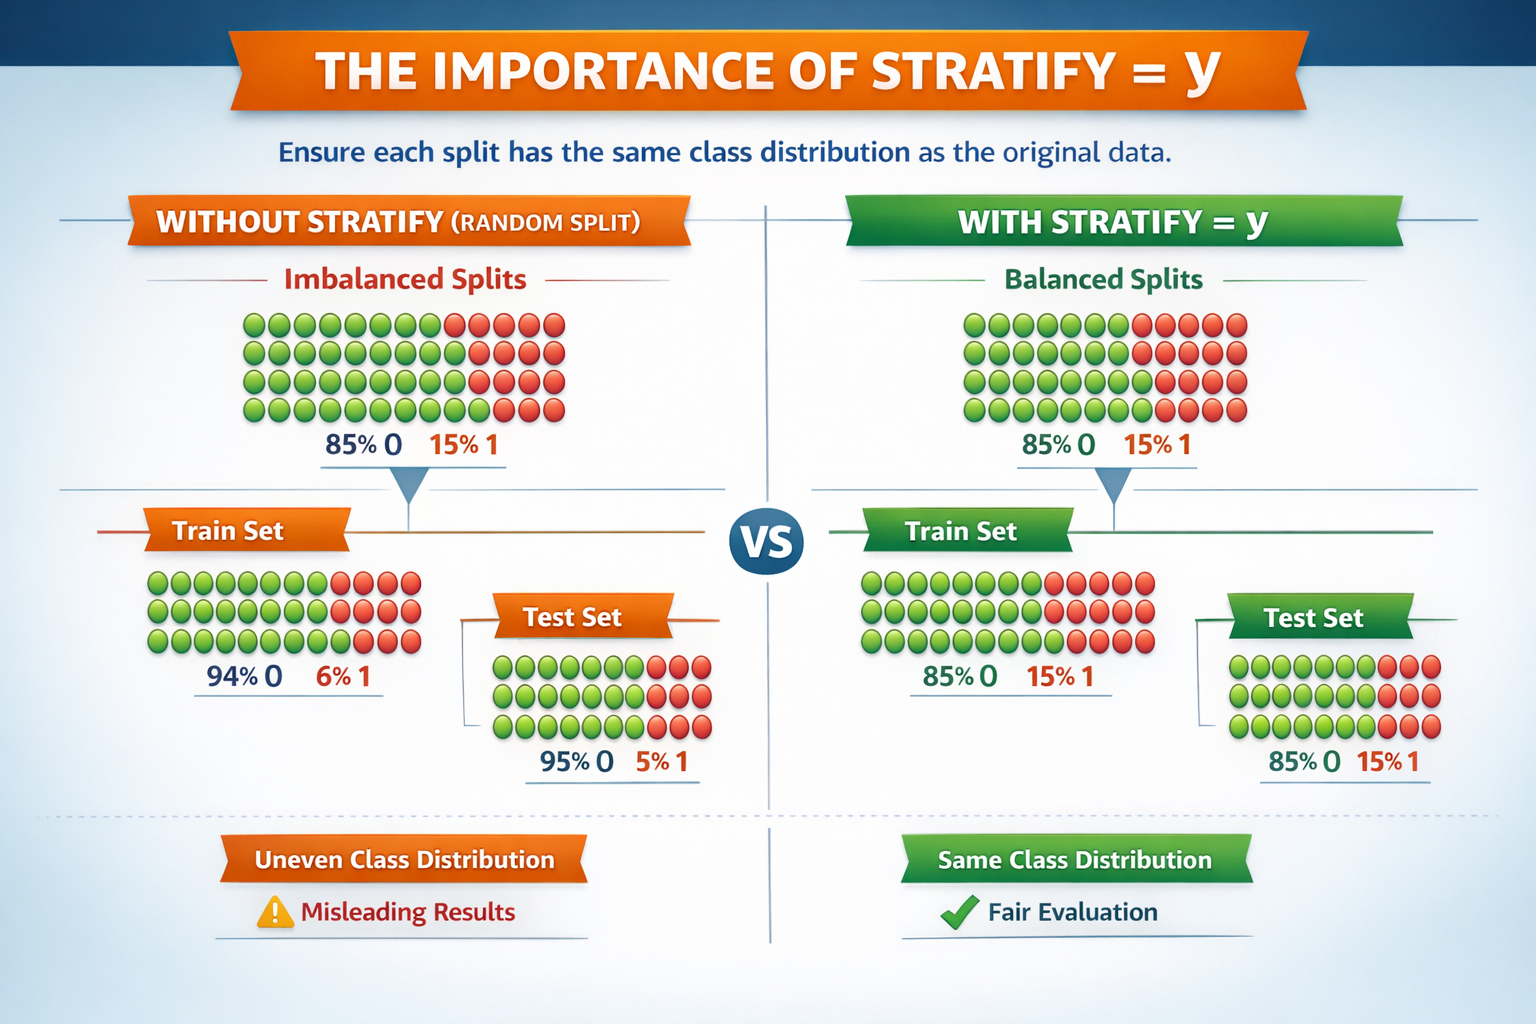

**WHY IS VALDATION TESTING REQUIRED?**

**->** to make decisions about the model(tuning) without touching the test dataset.

**The usage of these 3 datasets is different:**

The Training Dataset - Learing model parameters.

The Validation Dataset - Tuning model choices.

The Test Dataset - Fianl, unbiased evaluation.

Think of them as **study → practice → exam**.

**What goes wrong without validation?**

Scenario: Only Train + Test

Train a model

Evaluate on test set

Change hyperparameters

Evaluate again on test set

Repeat…

🔴 Problem:
You are learning from the test set indirectly.

Result:

Test accuracy becomes optimistic

Model fails on real-world data

This is called data leakage

Test set is no longer “unseen”

You’ve trained on it implicitly

**How validation fixes this**

Correct workflow

Train → Validate → Decide → Test (once)

1. Train model on training data

2. Tune:

    hyperparameters

    features

    thresholds using validation data

3. Lock the model

4. Evaluate once on test data

✔ Honest performance estimate
✔ Generalizable model

**Rule of Thumb**

Training set → learn

Validation set → decide

Test set → report

Touch the test set once. That’s it.

In [ ]:
model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(
        max_depth=25,
        random_state=42
    )
)

model.fit(x_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=25, random_state=42))])

**SIMPLE IMPUTER**

👉 SimpleImputer replaces missing values (NaN) with a fixed statistical value, learned only from the training data.

It is part of data preprocessing, not modeling.

⚠️ Most ML models (including DecisionTreeClassifier) cannot handle NaNs directly.

So:

Missing values must be handled before the model sees the data.

Here the strategy we used with Simple Imputer is "median", which is the correct strategy here for our medical data. Every NaN in a column is replaced by the column's median.


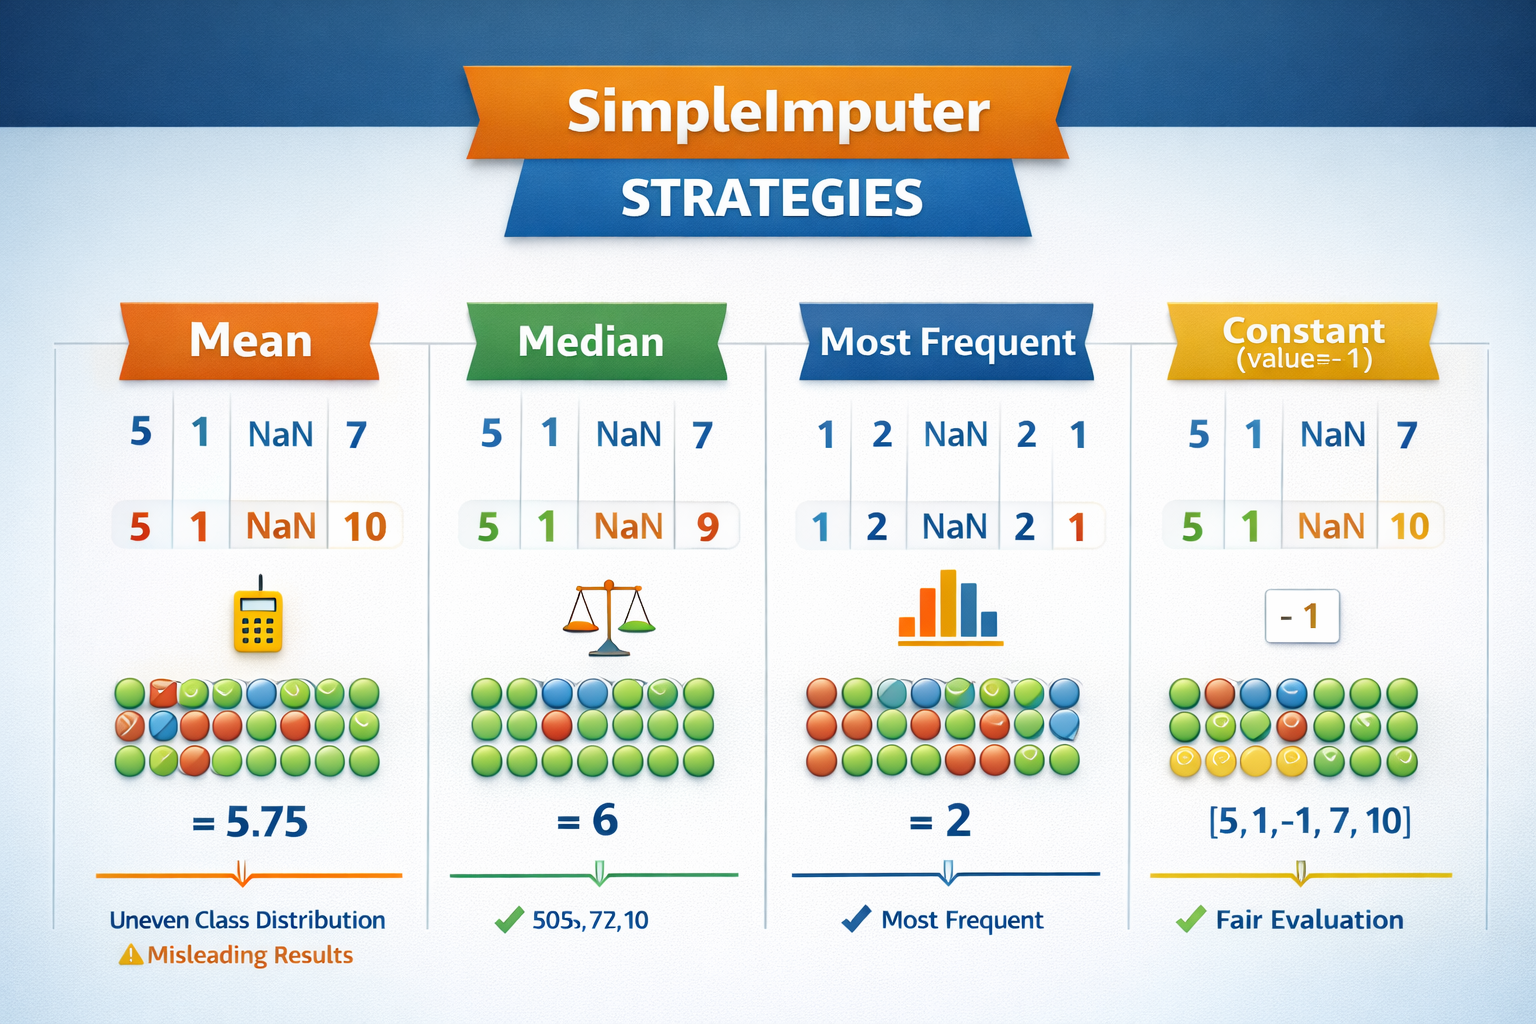

# **THE DECISION TREE CLASSIFIER**


A **Decision Tree Classifier** is a supervised machine learning algorithm that predicts a class by learning **decision rules** from data. It works like a structured flowchart of **if–else conditions**.

---

## 🌳 Visual Structure of a Decision Tree

![Image](https://images.openai.com/static-rsc-3/1dkR9kvb99D09fHyKjL7H2YFbnX6gAHa1O_9e_52ynR4nHgns1FIDnHwiAkBycIOlaAOEEePpkUmhs18uyDUCZZ5uWcpS0faRuoVdtfQCc0?purpose=fullsize\&v=1)


![Image](https://i.sstatic.net/iXc11.png)

---

## 1️⃣ Basic Idea

The tree asks questions like:

```
Is Age > 50?
    ├ Yes → Is BP > 140?
    │        ├ Yes → High Risk
    │        └ No  → Medium Risk
    └ No  → Low Risk
```

Each question splits data into smaller, more similar groups.

---

## 2️⃣ Key Components

| Component         | Meaning                        |
| ----------------- | ------------------------------ |
| **Root Node**     | First and most important split |
| **Decision Node** | Internal question              |
| **Leaf Node**     | Final prediction               |
| **Branch**        | Path based on condition        |

---

## 3️⃣ How Decision Tree Learns (Training Phase)

### Step A — Start with Full Dataset

Mixed classes (CHD = 0 and 1 together)

---

### Step B — Try All Possible Splits

For each feature, tree tries thresholds:

Example:

```
age ≤ 45
age ≤ 50
age ≤ 55
```

---

### Step C — Measure Split Quality (Impurity)

Most common metric → **Gini Impurity**

Formula:

```
Gini = 1 − Σ(p²)
```

Where p = probability of each class.

👉 Lower Gini = more pure node
👉 Tree chooses split with biggest impurity reduction

---

### Step D — Repeat Recursively

The same process repeats for each branch until stopping criteria are met.

---

## 4️⃣ Stopping Criteria (Prevents Overfitting)

Examples:

* Max depth reached
* Minimum samples per split reached
* Node becomes pure

Example from your code:

```python
DecisionTreeClassifier(max_depth=25)
```

Depth controls model complexity.

---

## 5️⃣ Prediction Phase (Very Fast ⚡)

For a new data point:

1. Start at root
2. Follow rules
3. Reach leaf
4. Output class

No heavy math — just comparisons.

---

## 6️⃣ Why It Works Well for Our Dataset

For Framingham-like medical tabular data:

✅ Handles nonlinear relations
✅ Handles feature interactions automatically
✅ Easy to interpret clinically

---

## 7️⃣ Why We Used This Pipeline

```
SimpleImputer → DecisionTreeClassifier
```

Because:

* Tree cannot handle NaNs
* Imputer fills missing values first

---

## 8️⃣ Advantages

✔ Works with numeric data directly
✔ No scaling needed
✔ Fast prediction

---

## 9️⃣ Disadvantages

❌ Can overfit (biggest issue)
❌ Unstable (small data change → new tree)
❌ Single tree weaker than ensembles

---

## 🔟 Real-Life Analogy

Doctor diagnosing patient:

* Ask symptom questions
* Narrow possibilities
* Give final diagnosis

That is exactly how a decision tree works.

In [ ]:
model.score(x_val, y_val)

0.7687776141384389

In [ ]:
model.score(x_train, y_train)

1.0

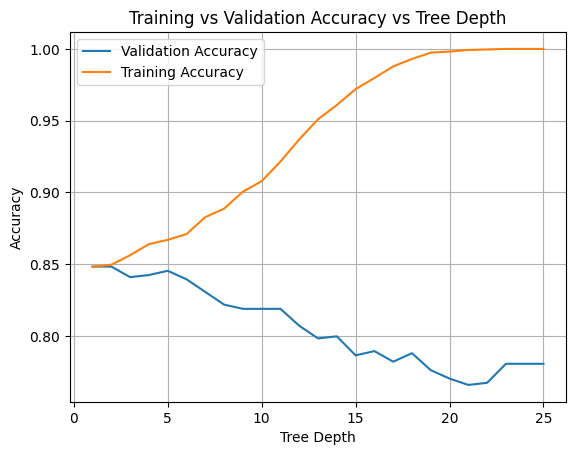

In [ ]:
Val_acc = []
Train_acc = []

for d in range(1, 26):
  model = make_pipeline(SimpleImputer(), DecisionTreeClassifier(max_depth=d,random_state=42))
  model.fit(x_train, y_train)
  Val_acc.append(model.score(x_val, y_val))
  Train_acc.append(model.score(x_train, y_train))

#Now plot both lists
plt.plot(range(1, 26), Val_acc, label = "Validation Accuracy")
plt.plot(range(1, 26), Train_acc, label = "Training Accuracy")
plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy vs Tree Depth")
plt.grid()
plt.legend()


## 🔍 What The Loop Is Doing

We are testing **25 different decision trees**:

```python
for d in range(1, 26):
```

👉 Depth = 1 → very simple model
👉 Depth = 25 → very complex model

---

## 🧩 Inside Each Iteration

### 1️⃣ Build Pipeline

```python
model = make_pipeline(
    SimpleImputer(),
    DecisionTreeClassifier(max_depth=d, random_state=42)
)
```

Meaning:

* Handle missing values using **SimpleImputer**
* Train tree with **depth = d**

This matches your pipeline logic:

```
SimpleImputer → DecisionTreeClassifier
```

---

### 2️⃣ Train Model

```python
model.fit(x_train, y_train)
```

Tree learns decision rules from training data.

---

### 3️⃣ Store Validation Accuracy

```python
Val_acc.append(model.score(x_val, y_val))
```

👉 Measures **generalization performance**
👉 This is what you should optimize.

---

### 4️⃣ Store Training Accuracy

```python
Train_acc.append(model.score(x_train, y_train))
```

👉 Measures **how well model memorizes training data**

---

## 📈 What The Plot Shows

```python
plt.plot(range(1, 26), Val_acc, label="Validation Accuracy")
plt.plot(range(1, 26), Train_acc, label="Training Accuracy")
```

We will usually see:

### Case 1 — Underfitting Zone

Small depth (1–3):

* Train accuracy → Low
* Validation accuracy → Low

Model too simple.

---

### Case 2 — Good Fit Zone ⭐

Medium depth (maybe 5–10 typically):

* Train accuracy → High
* Validation accuracy → Highest

Best model lives here.

---

### Case 3 — Overfitting Zone

Large depth (15–25):

* Train accuracy → ~100%
* Validation accuracy → Drops or plateaus

Model memorizing training data.

---

## 🎯 What We Should Select

Choose depth where:

```
Validation accuracy is maximum
AND
Gap between train and validation is small
```

Not where training accuracy is highest.

---

## 🧠 What This Technique Is Called

You are performing:
👉 **Hyperparameter tuning**
👉 Specifically: **Model complexity tuning**

---

## 📌 Why This Is Important

Without this:

```python
DecisionTreeClassifier(max_depth=25)
```

We might be:

* Overfitting badly
* Getting misleading performance

---

## 🧪 Real ML Insight

Decision Trees:

* Low depth → High bias (underfit)
* High depth → High variance (overfit)

Our plot visualizes **Bias–Variance tradeoff** 📊

In [ ]:
# Oversample ONLY training
# Oversampling is a data preprocessing technique used to address class imbalance, where one class (majority) heavily outnumbers another (minority),
# often in tasks like fraud detection or medical diagnosis.

over_sampler = RandomOverSampler(random_state=42)
x_train_over, y_train_over = over_sampler.fit_resample(x_train, y_train)

print("Original train shape:", x_train.shape)
print("Oversampled train shape:", x_train_over.shape)

Original train shape: (2713, 15)
Oversampled train shape: (4602, 15)


**Why Oversampling helps here**

Framingham-like dataset:

CHD positive ≈ 15%

Model may bias toward predicting 0

Oversampling:

Forces model to see more CHD cases

Improves recall for minority class

In [ ]:
model2 = make_pipeline(SimpleImputer(), RandomForestClassifier())
print(model2)

Pipeline(steps=[('simpleimputer', SimpleImputer()),
                ('randomforestclassifier', RandomForestClassifier())])


**Random Forest is:**

👉 Many Decision Trees

👉 Each trained on random subset of data

👉 Final prediction = voting from all trees

🌳 Visual Idea of Random Forest

Instead of ONE tree:

Tree 1 → Predict CHD

Tree 2 → Predict CHD

Tree 3 → Predict No CHD

Tree 4 → Predict CHD

Final answer → Majority Vote

⭐ Why Random Forest Is Better Than Single Tree

Decision Tree	-> Overfits easily, High Variance, Single Decision Path

Random Forest -> Much more stable, Lower variance, Ensemble learning

In [ ]:
# K Cross Validation
cv_acc_scores = cross_val_score(model2, x_train_over, y_train_over, cv = 5, n_jobs=-1)
print(cv_acc_scores)
print("Mean CV Accuracy:", cv_acc_scores.mean())

[0.98045603 0.96959826 0.97282609 0.97608696 0.97826087]
Mean CV Accuracy: 0.9754456403719963


🧠 **What Cross Validation Means**

Instead of:

👉 Training once

👉 Validating once

You now:

👉 Train 5 different times

👉 Validate 5 different times

👉 Average performance

This gives a more reliable performance estimate.

📊 How 5-Fold Cross Validation Works

Suppose training data is split into 5 parts:

Fold 1 → Test | Train Train Train Train

Fold 2 → Train | Test Train Train Train

Fold 3 → Train | Train Test Train Train

Fold 4 → Train | Train Train Test Train

Fold 5 → Train | Train Train Train Test

Each fold:

Uses different validation data

Reduces randomness bias

In [ ]:
params = {
    "simpleimputer__strategy": ["mean", "median"],
    "randomforestclassifier__n_estimators": [10, 100],
    "randomforestclassifier__max_depth": [2, 10, 30]
}

In [ ]:
#We'll use Grid Search CV(Cross Valuation) to calculate every possible pramaeter combination

model_main = GridSearchCV(
    model2,
    param_grid=params,
    cv=5,
    n_jobs=-1,
    verbose=1,
    scoring="roc_auc"
)

In [ ]:
model_main.fit(x_train_over, y_train_over)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('simpleimputer', SimpleImputer()),
                                       ('randomforestclassifier',
                                        RandomForestClassifier())]),
             n_jobs=-1,
             param_grid={'randomforestclassifier__max_depth': [2, 10, 30],
                         'randomforestclassifier__n_estimators': [10, 100],
                         'simpleimputer__strategy': ['mean', 'median']},
             scoring='roc_auc', verbose=1)

In [ ]:
cv_results = pd.DataFrame(model_main.cv_results_)
cv_results.head(10)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_randomforestclassifier__max_depth,param_randomforestclassifier__n_estimators,param_simpleimputer__strategy,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.069988,0.024235,0.018926,0.006385,2,10,mean,"{'randomforestclassifier__max_depth': 2, 'rand...",0.744756,0.707458,0.728842,0.739572,0.694275,0.722981,0.019229,11
1,0.101859,0.027269,0.020047,0.004937,2,10,median,"{'randomforestclassifier__max_depth': 2, 'rand...",0.744530,0.712874,0.729166,0.714690,0.695718,0.719396,0.016447,12
2,0.479222,0.081028,0.023168,0.000422,2,100,mean,"{'randomforestclassifier__max_depth': 2, 'rand...",0.749635,0.717877,0.742880,0.739813,0.701805,0.730402,0.017826,10
3,0.375085,0.016780,0.023672,0.000927,2,100,median,"{'randomforestclassifier__max_depth': 2, 'rand...",0.749345,0.720871,0.737880,0.735733,0.714943,0.731754,0.012360,9
4,0.085470,0.003061,0.010755,0.000398,10,10,mean,"{'randomforestclassifier__max_depth': 10, 'ran...",0.954164,0.956979,0.950614,0.961446,0.954577,0.955556,0.003579,7
5,0.089266,0.002587,0.010454,0.000630,10,10,median,"{'randomforestclassifier__max_depth': 10, 'ran...",0.933969,0.954291,0.941503,0.973913,0.950281,0.950791,0.013538,8
6,0.735984,0.019673,0.034166,0.001328,10,100,mean,"{'randomforestclassifier__max_depth': 10, 'ran...",0.967391,0.969985,0.970000,0.983053,0.976777,0.973441,0.005725,5
7,0.757044,0.044589,0.035041,0.002272,10,100,median,"{'randomforestclassifier__max_depth': 10, 'ran...",0.963826,0.973743,0.968960,0.983138,0.973596,0.972653,0.006381,6
8,0.106248,0.009163,0.011362,0.001892,30,10,mean,"{'randomforestclassifier__max_depth': 30, 'ran...",0.989682,0.998654,0.998984,0.999653,0.999771,0.997349,0.003856,3
9,0.105589,0.003252,0.010905,0.000408,30,10,median,"{'randomforestclassifier__max_depth': 30, 'ran...",0.988352,0.997123,0.998443,0.998615,0.998842,0.996275,0.004006,4


In [ ]:
best_model = model_main.best_estimator_

test_score = best_model.score(x_test, y_test)
print("Test Score:", test_score)

Test Score: 0.8254716981132075


In [ ]:
male = widgets.IntText(description="Male (0/1):")
age = widgets.IntText(description="Age:")
education = widgets.FloatText(description="Education:")
currentSmoker = widgets.IntText(description="Smoker (0/1):")
cigsPerDay = widgets.FloatText(description="Cigs/Day:")
BPMeds = widgets.IntText(description="BP Meds (0/1):")
prevalentStroke = widgets.IntText(description="Stroke (0/1):")
prevalentHyp = widgets.IntText(description="Hypertension (0/1):")
diabetes = widgets.IntText(description="Diabetes (0/1):")
totChol = widgets.FloatText(description="Cholesterol:")
sysBP = widgets.FloatText(description="Sys BP:")
diaBP = widgets.FloatText(description="Dia BP:")
BMI = widgets.FloatText(description="BMI:")
heartRate = widgets.FloatText(description="Heart Rate:")
glucose = widgets.FloatText(description="Glucose:")

predict_btn = widgets.Button(description="Predict CHD Risk")
output = widgets.Output()

In [ ]:
def predict_chd(b):
    with output:
        output.clear_output()

        data = pd.DataFrame([{
            "male": male.value,
            "age": age.value,
            "education": education.value,
            "currentSmoker": currentSmoker.value,
            "cigsPerDay": cigsPerDay.value,
            "BPMeds": BPMeds.value,
            "prevalentStroke": prevalentStroke.value,
            "prevalentHyp": prevalentHyp.value,
            "diabetes": diabetes.value,
            "totChol": totChol.value,
            "sysBP": sysBP.value,
            "diaBP": diaBP.value,
            "BMI": BMI.value,
            "heartRate": heartRate.value,
            "glucose": glucose.value
        }])

        pred = best_model.predict(data)[0]

        if pred == 1:
            print("⚠ High Risk of CHD")
        else:
            print("✅ Low Risk of CHD")

In [ ]:
predict_btn.on_click(predict_chd)

In [ ]:
display(
    male, age, education, currentSmoker, cigsPerDay,
    BPMeds, prevalentStroke, prevalentHyp, diabetes,
    totChol, sysBP, diaBP, BMI, heartRate, glucose,
    predict_btn, output
)

IntText(value=0, description='Male (0/1):')

IntText(value=0, description='Age:')

FloatText(value=0.0, description='Education:')

IntText(value=0, description='Smoker (0/1):')

FloatText(value=0.0, description='Cigs/Day:')

IntText(value=0, description='BP Meds (0/1):')

... (7 outputs left out)

FloatText(value=0.0, description='Heart Rate:')

FloatText(value=0.0, description='Glucose:')

Button(description='Predict CHD Risk', style=ButtonStyle())

Output()